<a href="https://colab.research.google.com/github/Seraphim-Vasilis-Partsakoulakis/Transparent-logistic-baseline/blob/main/Week_5_Assignment_Transparent_Logistic_Baseline_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 23112026
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print(f"Environment initialized. Random seed: {RANDOM_STATE}")

Environment initialized. Random seed: 23112026


1.Targeting Prevalence and Data-Quality Audit

In [2]:
# @title
SAMPLE_URL = (
    "https://raw.githubusercontent.com/fkottas/Teaching-Courses/main/"
    "Machine%20Learning%20in%20Finance/2026-2027/lectures/week-05/data/credit_ml_sample.csv"
)

df = pd.read_csv(SAMPLE_URL)

candidate_targets = [c for c in df.columns if "default" in c.lower() or c.lower() in ["y", "target"]]
target_col = candidate_targets[0] if candidate_targets else df.columns[-1]

definition_table = pd.DataFrame({
    "Component": [
        "Dataset Loaded",
        "One Row (Observation Unit)",
        "Positive Event (Y = 1)",
        "Outcome Horizon (t_0 + 1)",
        "Information Cutoff (t_0)"
    ],
    "Formal_Definition": [
        f"credit_ml_sample.csv ({df.shape[0]:,} rows x {df.shape[1]} columns)",
        "One individual credit card borrower i observed at cutoff t_0",
        f"{target_col} == 1 (borrower defaults during the forward outcome horizon)",
        "Forward-looking 1-period default window strictly after t_0 (t_0 + 1)",
        "Prediction timestamp t_0; all predictors X_i are strictly measured at t <= t_0"
    ]
})

print("Deliverable 1: Problem Structure and Temporal Definitions")
display(definition_table)

print(f"\nDetected Target Column: '{target_col}'")
print(f"Dataset Columns ({len(df.columns)}): {list(df.columns)}\n")
display(df.head(5))

Deliverable 1: Problem Structure and Temporal Definitions


,Component,Formal_Definition
0,Dataset Loaded,"credit_ml_sample.csv (1,000 rows x 20 columns)"
1,One Row (Observation Unit),One individual credit card borrower i observed...
2,Positive Event (Y = 1),default_next_month == 1 (borrower defaults dur...
3,Outcome Horizon (t_0 + 1),Forward-looking 1-period default window strict...
4,Information Cutoff (t_0),Prediction timestamp t_0; all predictors X_i a...



Detected Target Column: 'default_next_month'
Dataset Columns (20): ['ID', 'LIMIT_BAL', 'PAY_0', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2', 'default_next_month', 'utilization', 'total_bill_6m', 'total_paid_6m', 'payment_to_bill_6m', 'overdue_count_6m', 'max_delay_6m', 'recent_overdue', 'high_utilization', 'stress_flag', 'bill_change_1m', 'payment_change_1m', 'log_limit']



,ID,LIMIT_BAL,PAY_0,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2,default_next_month,utilization,total_bill_6m,total_paid_6m,payment_to_bill_6m,overdue_count_6m,max_delay_6m,recent_overdue,high_utilization,stress_flag,bill_change_1m,payment_change_1m,log_limit
0,1,20000,2,3913,3102,0,689,1,0.1956,7704,689,0.0894,2,2,1,0,0,811,-689,9.9035
1,2,120000,-1,2682,1725,0,1000,1,0.0223,17077,5000,0.2928,2,2,0,0,0,957,-1000,11.6953
2,3,90000,0,29239,14027,1518,1500,0,0.3249,101653,11018,0.1084,0,0,0,0,0,15212,18,11.4076
3,4,50000,0,46990,48233,2000,2019,0,0.9398,231334,8388,0.0363,0,0,0,1,0,-1243,-19,10.8198
4,5,50000,-1,8617,5670,2000,36681,0,0.1723,109339,59049,0.5401,0,0,0,0,0,2947,-34681,10.8198


2.Reporting the target prevalence and one data-quality observation.

In [3]:
# @title
target_col = "default_next_month"

target_counts = df[target_col].value_counts().sort_index()
target_prevalence = df[target_col].mean()

audit_df = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "n_unique": df.nunique(),
})

print(f"Target Prevalence ({target_col} == 1): {target_prevalence:.4f} ({100 * target_prevalence:.2f}%)")
print("\nTarget Counts:")
print(target_counts.to_string())

print("\nData-Quality Audit Summary:")
display(audit_df)

missing_cols = audit_df[audit_df["missing_n"] > 0]
print("\nColumns with Missing Values:")
display(missing_cols)

Target Prevalence (default_next_month == 1): 0.2140 (21.40%)

Target Counts:
default_next_month
0    786
1    214

Data-Quality Audit Summary:


,dtype,missing_n,missing_pct,n_unique
ID,int64,0,0.0000,1000
LIMIT_BAL,int64,0,0.0000,56
PAY_0,int64,0,0.0000,8
BILL_AMT1,int64,0,0.0000,904
BILL_AMT2,int64,0,0.0000,875
PAY_AMT1,int64,0,0.0000,521
PAY_AMT2,int64,0,0.0000,520
default_next_month,int64,0,0.0000,2
utilization,float64,0,0.0000,923
total_bill_6m,int64,0,0.0000,961



Columns with Missing Values:


,dtype,missing_n,missing_pct,n_unique
payment_to_bill_6m,float64,35,3.5000,912


3. Logistic Regression Mathematics: Score, Sigmoid, Odds, Likelihood, and Log-Loss

In [4]:
# @title
beta_0 = -1.40
beta_1 = 1.80
beta_2 = 0.45

x1 = np.array([0.20, 0.85, 0.60, 0.10])
x2 = np.array([0.0, 2.0, 1.0, 0.0])
y_toy = np.array([0, 1, 1, 0])

z = beta_0 + beta_1 * x1 + beta_2 * x2

p_hat = 1.0 / (1.0 + np.exp(-z))

odds = p_hat / (1.0 - p_hat)

obs_likelihood = (p_hat ** y_toy) * ((1.0 - p_hat) ** (1.0 - y_toy))
sample_likelihood = np.prod(obs_likelihood)

manual_log_loss = -np.mean(y_toy * np.log(p_hat) + (1.0 - y_toy) * np.log(1.0 - p_hat))
sklearn_log_loss = log_loss(y_toy, p_hat)

check_df = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "y": y_toy,
    "z_score": z,
    "p_hat": p_hat,
    "odds": odds,
    "obs_likelihood": obs_likelihood,
})

display(check_df)
print(f"Sample Likelihood: {sample_likelihood:.6e}")
print(f"Manual Log-Loss:   {manual_log_loss:.6f} | sklearn log_loss: {sklearn_log_loss:.6f}")

,x1,x2,y,z_score,p_hat,odds,obs_likelihood
0,0.2000,0.0000,0,-1.0400,0.2611,0.3535,0.7389
1,0.8500,2.0000,1,1.0300,0.7369,2.8011,0.7369
2,0.6000,1.0000,1,0.1300,0.5325,1.1388,0.5325
3,0.1000,0.0000,0,-1.2200,0.2279,0.2952,0.7721


Sample Likelihood: 2.238255e-01
Manual Log-Loss:   0.374222 | sklearn log_loss: 0.374222


4. Regularized Logistic Regression Comparison: Ridge, LASSO, and Elastic Net

In [5]:
# @title
target_col = "default_next_month"
drop_cols = [c for c in ["ID", target_col] if c in df.columns]

X = df.drop(columns=drop_cols).copy()
y = df[target_col].astype(int).copy()

TEST_SIZE = 0.21

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
c_grid = [0.01, 0.1, 1.0, 5.0, 10.0, 25.0 , 100.0]
l1_ratio_grid = [0.2, 0.5, 1.0]

results_rows = []
fitted_models = {}

ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE)),
])
ridge_search = GridSearchCV(
    ridge_pipe,
    param_grid={"clf__C": c_grid},
    scoring="neg_log_loss",
    cv=cv_splitter,
    n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
fitted_models["Ridge (L2)"] = ridge_search.best_estimator_

lasso_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l1", solver="saga", max_iter=5000, random_state=RANDOM_STATE)),
])
lasso_search = GridSearchCV(
    lasso_pipe,
    param_grid={"clf__C": c_grid},
    scoring="neg_log_loss",
    cv=cv_splitter,
    n_jobs=-1,
)
lasso_search.fit(X_train, y_train)
fitted_models["LASSO (L1)"] = lasso_search.best_estimator_

enet_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=5000,
        random_state=RANDOM_STATE,
    )),
])
enet_search = GridSearchCV(
    enet_pipe,
    param_grid={"clf__C": c_grid, "clf__l1_ratio": l1_ratio_grid},
    scoring="neg_log_loss",
    cv=cv_splitter,
    n_jobs=-1,
)
enet_search.fit(X_train, y_train)
fitted_models["Elastic Net"] = enet_search.best_estimator_

for model_name, model in fitted_models.items():
    test_proba = model.predict_proba(X_test)[:, 1]
    coef_vec = model.named_steps["clf"].coef_.ravel()
    nonzero_coefs = int(np.sum(np.abs(coef_vec) > 1e-6))

    results_rows.append({
        "Model": model_name,
        "Selected_Hyperparameters": str(
            ridge_search.best_params_ if model_name == "Ridge (L2)"
            else lasso_search.best_params_ if model_name == "LASSO (L1)"
            else enet_search.best_params_
        ),
        "CV_LogLoss": -ridge_search.best_score_ if model_name == "Ridge (L2)"
            else -lasso_search.best_score_ if model_name == "LASSO (L1)"
            else -enet_search.best_score_,
        "Test_LogLoss": log_loss(y_test, test_proba),
        "Test_Brier_Score": brier_score_loss(y_test, test_proba),
        "Test_ROC_AUC": roc_auc_score(y_test, test_proba),
        "Nonzero_Features": f"{nonzero_coefs}/{len(coef_vec)}",
    })

comparison_df = pd.DataFrame(results_rows)
print("Regularized Logistic Regression Comparison (Selected on Train CV, Evaluated on Test)")
display(comparison_df)

Regularized Logistic Regression Comparison (Selected on Train CV, Evaluated on Test)


,Model,Selected_Hyperparameters,CV_LogLoss,Test_LogLoss,Test_Brier_Score,Test_ROC_AUC,Nonzero_Features
0,Ridge (L2),{'clf__C': 0.01},0.4740,0.4619,0.1472,0.7088,18/18
1,LASSO (L1),{'clf__C': 0.1},0.4763,0.4570,0.1453,0.7148,7/18
2,Elastic Net,"{'clf__C': 0.01, 'clf__l1_ratio': 0.2}",0.4722,0.4665,0.1484,0.6937,4/18


5. Coefficient Interpretation in Odds Language

In [6]:
# @title
chosen_model = fitted_models["LASSO (L1)"]
clf_step = chosen_model.named_steps["clf"]
feature_names = list(X_train.columns)
coefs = clf_step.coef_.ravel()

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coef_Beta": coefs,
    "Odds_Ratio_exp_beta": np.exp(coefs),
    "Pct_Change_in_Odds": (np.exp(coefs) - 1.0) * 100.0,
})

nonzero_df = coef_table[coef_table["Coef_Beta"].abs() > 1e-6].sort_values(
    by="Coef_Beta", key=np.abs, ascending=False
)

print("Non-zero coefficients in LASSO (L1) (standardized features):")
display(nonzero_df)

selected_row = nonzero_df.iloc[5]
feat_name = selected_row["Feature"]
beta_val = float(selected_row["Coef_Beta"])
or_val = float(selected_row["Odds_Ratio_exp_beta"])
pct_odds_change = float(selected_row["Pct_Change_in_Odds"])

print(f"\nSelected Feature: {feat_name}")
print(f"Estimated beta (standardized): {beta_val:.4f}")
print(f"Odds Ratio exp(beta):          {or_val:.4f}")
print(f"Implied change in odds:        {pct_odds_change:+.2f}% per +1 SD (holding other features fixed)")

Non-zero coefficients in LASSO (L1) (standardized features):


,Feature,Coef_Beta,Odds_Ratio_exp_beta,Pct_Change_in_Odds
12,recent_overdue,0.4494,1.5673,56.7309
10,overdue_count_6m,0.2175,1.2430,24.2981
11,max_delay_6m,0.1656,1.1802,18.0154
14,stress_flag,-0.0853,0.9182,-8.1761
4,PAY_AMT1,-0.0637,0.9383,-6.1724
3,BILL_AMT2,0.0489,1.0501,5.0111
9,payment_to_bill_6m,0.0069,1.0070,0.6950



Selected Feature: BILL_AMT2
Estimated beta (standardized): 0.0489
Odds Ratio exp(beta):          1.0501
Implied change in odds:        +5.01% per +1 SD (holding other features fixed)


6. Decision Threshold Comparison and False Positive vs. False Negative Trade-Off

Decision Threshold Comparison on Held-Out Test Set (LASSO L1)


,Threshold_tau,TP (Caught_Defaults),FN (Missed_Defaults),FP (False_Alarms),TN (Correct_NonDefaults),Precision,Recall (Sensitivity),Accuracy,Flagged_Rate
0,0.2000,28,17,34,131,0.4516,0.6222,0.7571,0.2952
1,0.4000,15,30,11,154,0.5769,0.3333,0.8048,0.1238


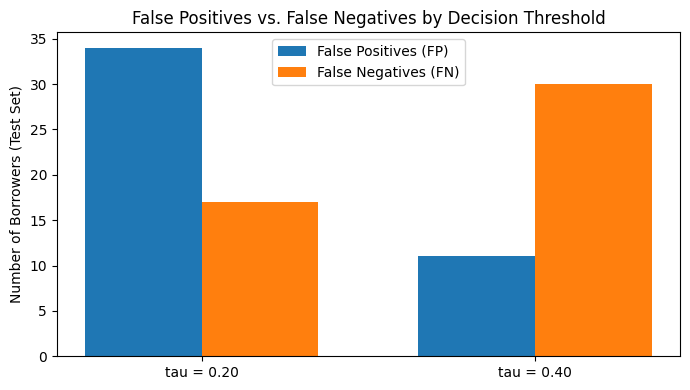

In [7]:
# @title
best_model = fitted_models["LASSO (L1)"]
y_test_proba = best_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.40]

threshold_rows = []
for tau in thresholds:
    y_pred_tau = (y_test_proba >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()

    threshold_rows.append({
        "Threshold_tau": tau,
        "TP (Caught_Defaults)": int(tp),
        "FN (Missed_Defaults)": int(fn),
        "FP (False_Alarms)": int(fp),
        "TN (Correct_NonDefaults)": int(tn),
        "Precision": precision_score(y_test, y_pred_tau, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_test, y_pred_tau, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_pred_tau),
        "Flagged_Rate": float(y_pred_tau.mean()),
    })

threshold_df = pd.DataFrame(threshold_rows)
print("Decision Threshold Comparison on Held-Out Test Set (LASSO L1)")
display(threshold_df)

fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(len(thresholds))
width = 0.35

ax.bar(x_pos - width / 2, threshold_df["FP (False_Alarms)"], width, label="False Positives (FP)")
ax.bar(x_pos + width / 2, threshold_df["FN (Missed_Defaults)"], width, label="False Negatives (FN)")

ax.set_xticks(x_pos)
ax.set_xticklabels([f"tau = {t:.2f}" for t in thresholds])
ax.set_ylabel("Number of Borrowers (Test Set)")
ax.set_title("False Positives vs. False Negatives by Decision Threshold")
ax.legend()
plt.tight_layout()
plt.show()

### Explanation of the FP vs. FN Trade-Off

Changing the decision threshold $\tau$ shifts where the model draws the line between predicting default ($\hat{p}_i \ge \tau$) and predicting non-default ($\hat{p}_i < \tau$), creating a direct trade-off between **False Positives (FP)** and **False Negatives (FN)**:

* **At the lower threshold ($\tau = 0.20$)**: More borrowers cross the cutoff, so the model catches more actual defaulters (**fewer FN**, higher **Recall**). The trade-off is a higher number of **FP**—borrowers flagged as risky who would not actually default—which can lead to unnecessary friction, manual review, or tighter credit terms.
* **At the higher threshold ($\tau = 0.40$)**: Fewer borrowers are flagged, so **FP** drops and **Precision** rises, avoiding unnecessary false alarms on safe borrowers. However, **FN** increases because borrowers with moderate-to-high risk below $0.40$ are not flagged in advance.

In credit risk, **FN** and **FP** do not carry equal economic weight: missing an actual default (**FN**) typically exposes the lender to direct credit loss, whereas a **FP** primarily involves screening cost, customer friction, or opportunity cost. Therefore, the choice of $\tau$ should reflect the relative cost of these two errors rather than relying mechanically on $\tau = 0.40$.

7. Key Limitation, Alternative / Next Step, and Summary Takeaway

In [8]:
# @title
COST_FN = 3.8
COST_FP = 1.0

best_model = fitted_models["LASSO (L1)"]
y_test_proba = best_model.predict_proba(X_test)[:, 1]

candidate_taus = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

cost_rows = []
for tau in candidate_taus:
    y_pred_tau = (y_test_proba >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tau).ravel()
    expected_cost = COST_FN * fn + COST_FP * fp

    cost_rows.append({
        "Threshold_tau": tau,
        "FP": int(fp),
        "FN": int(fn),
        "Expected_Cost": float(expected_cost),
    })

cost_df = pd.DataFrame(cost_rows).sort_values(by="Expected_Cost", ascending=True)
print(f"Expected Misclassification Cost Check (COST_FN={COST_FN}, COST_FP={COST_FP}):")
display(cost_df)

Expected Misclassification Cost Check (COST_FN=3.8, COST_FP=1.0):


,Threshold_tau,FP,FN,Expected_Cost
1,0.2000,34,17,98.6000
2,0.3000,27,21,106.8000
3,0.4000,11,30,125.0000
4,0.5000,7,38,151.4000
5,0.6000,2,42,161.6000
0,0.1000,163,0,163.0000
